# 05. Exploratory Data Analysis (EDA) - Marine Heatwaves (MHW) 5 Wilayah

Notebook ini menganalisis dataset **Marine Heatwaves (MHW) Labels** harian periode **2015–2025** pada 5 wilayah perairan observasi:
1. **Pasifik Niño 3.4** (5°LS–5°LU, 170°BB–120°BB)
2. **Selat Makassar** (5°LS–2°LU, 116°BT–120°BT)
3. **Selat Karimata** (3°LS–2°LU, 105°BT–110°BT)
4. **Selatan Jawa** (12°LS–8°LS, 105°BT–115°BT)
5. **Maluku Utara–Papua** (3°LS–3°LU, 125°BT–140°BT)

### Latar Belakang Ilmiah & Definisi MHW:
- Merujuk pada framework ilmiah **Hobday et al. (2016)**, gelombang panas laut (*Marine Heatwave*) didefinisikan sebagai peristiwa anomali suhu air laut hangat yang:
  1. Melampaui ambang batas **persentil ke-90 ($P_{90}$)** dari klimatologi musiman setempat.
  2. Bertahan selama **minimal 5 hari berturut-turut** ($duration \ge 5	ext{ hari}$).
- **Penting**: Ambang MHW dihitung secara lokal dan musiman, sehingga *berbeda secara fundamental* dari ambang klasifikasi ENSO (±0.5°C di Niño 3.4). Label MHW merefleksikan stres termal ekstrem lokal pada ekosistem laut (seperti pemutihan karang / *coral bleaching* dan mortalitas perikanan).

### Tujuan Analisis:
1. Memverifikasi integritas, rentang tanggal (4.001 hari dari 2015–2025), dan struktur dataset label MHW.
2. Memvisualisasikan deteksi MHW harian pada masing-masing 5 wilayah (kurva SST vs baseline persentil ke-90).
3. Menganalisis total hari, proporsi durasi, dan perbandingan tingkat keparahan MHW antar wilayah.
4. Mengekstraksi metrik peristiwa individu Hobday (*event duration*, *maximum intensity*, dan *cumulative intensity*).
5. Menganalisis tren tahunan kejadian MHW (2015–2025) untuk menguji hipotesis peningkatan frekuensi pemanasan laut.
6. Mengidentifikasi siklus musiman bulanan kerentanan MHW per wilayah.
7. Menganalisis ko-insidensi spasial (*spatial co-occurrence*) dan keterkaitan antara MHW regional dengan peristiwa El Niño.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 10

# Konfigurasi Path
DATA_DIR = Path("dataset/data_mhw") if Path("dataset/data_mhw").exists() else Path("../dataset/data_mhw")
OUTPUT_DIR = Path("reports/figures") if Path("reports").exists() else Path("../reports/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = DATA_DIR / "mhw_labels.csv"

WILAYAH = [
    "Pasifik_Nino34",
    "Selat_Makassar",
    "Selat_Karimata",
    "Selatan_Jawa",
    "Maluku_Utara_Papua"
]

print(f"Path dataset MHW: {CSV_PATH.resolve()}")
print(f"Path output figures: {OUTPUT_DIR.resolve()}")

Path dataset MHW: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\data_mhw\mhw_labels.csv
Path output figures: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures


## 2. Memuat Data dan Verifikasi Integritas

Dataset berisi deret waktu harian dengan 15 kolom:
- Untuk setiap wilayah: `{wilayah}_sst`, `{wilayah}_p90`, dan `{wilayah}_is_mhw`.
- Indeks adalah timestamp harian dari `2015-01-01` sampai `2025-12-31` (total 4.001 hari observasi).

In [2]:
# Memuat dataset
df_mhw = pd.read_csv(CSV_PATH, index_col=0)
df_mhw.index = pd.to_datetime(df_mhw.index)

print("=== INFORMASI DATASET MHW ===")
print(f"Bentuk data: {df_mhw.shape[0]} baris x {df_mhw.shape[1]} kolom")
print(f"Rentang Tanggal: {df_mhw.index.min().strftime('%Y-%m-%d')} s.d. {df_mhw.index.max().strftime('%Y-%m-%d')}")
print("\nPengecekan Missing Value:")
print(df_mhw.isnull().sum())
print("\nContoh 5 baris pertama:")
display(df_mhw.head())

=== INFORMASI DATASET MHW ===
Bentuk data: 4001 baris x 15 kolom
Rentang Tanggal: 2015-01-01 s.d. 2025-12-31

Pengecekan Missing Value:
Pasifik_Nino34_sst           0
Pasifik_Nino34_p90           0
Pasifik_Nino34_is_mhw        0
Selat_Makassar_sst           0
Selat_Makassar_p90           0
Selat_Makassar_is_mhw        0
Selat_Karimata_sst           0
Selat_Karimata_p90           0
Selat_Karimata_is_mhw        0
Selatan_Jawa_sst             0
Selatan_Jawa_p90             0
Selatan_Jawa_is_mhw          0
Maluku_Utara_Papua_sst       0
Maluku_Utara_Papua_p90       0
Maluku_Utara_Papua_is_mhw    0
dtype: int64

Contoh 5 baris pertama:


,Pasifik_Nino34_sst,Pasifik_Nino34_p90,Pasifik_Nino34_is_mhw,Selat_Makassar_sst,Selat_Makassar_p90,Selat_Makassar_is_mhw,Selat_Karimata_sst,Selat_Karimata_p90,Selat_Karimata_is_mhw,Selatan_Jawa_sst,Selatan_Jawa_p90,Selatan_Jawa_is_mhw,Maluku_Utara_Papua_sst,Maluku_Utara_Papua_p90,Maluku_Utara_Papua_is_mhw
time,,,,,,,,,,,,,,,
2015-01-01 12:00:00,26.627192,28.556633,0,29.316582,29.623924,0,28.672382,29.314772,0,28.889095,29.816643,0,29.575830,30.048904,0
2015-01-02 12:00:00,26.662533,28.540373,0,29.317404,29.640694,0,28.459430,29.167074,0,28.777308,29.690184,0,29.567276,30.057899,0
2015-01-03 12:00:00,26.689571,28.522779,0,29.286520,29.606678,0,28.364906,29.374931,0,28.829336,29.510122,0,29.535147,30.002777,0
2015-01-04 12:00:00,26.724104,28.482571,0,29.281708,29.615414,0,28.463875,29.279921,0,28.873768,29.092707,0,29.507260,29.983643,0
2015-01-05 12:00:00,26.746600,28.412909,0,29.274618,29.670317,0,28.445908,29.235634,0,28.860243,29.169712,0,29.447506,29.982174,0


## 3. Visualisasi Deteksi Gelombang Panas Laut Tiap Wilayah (SST vs P90)

Visualisasi panel berikut memperlihatkan perbandingan deret waktu harian SST, garis batas persentil ke-90 musiman, dan shading area merah ketika terjadi status **MHW aktif** ($is\_mhw = 1$).
Karakteristik dinamika termal yang sangat berbeda tampak antara perairan tropis tertutup (Selat Makassar, Selat Karimata) dan perairan upwelling terbuka (Selatan Jawa, Pasifik Niño 3.4).

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\27_mhw_detection_timeline_5_regions.png


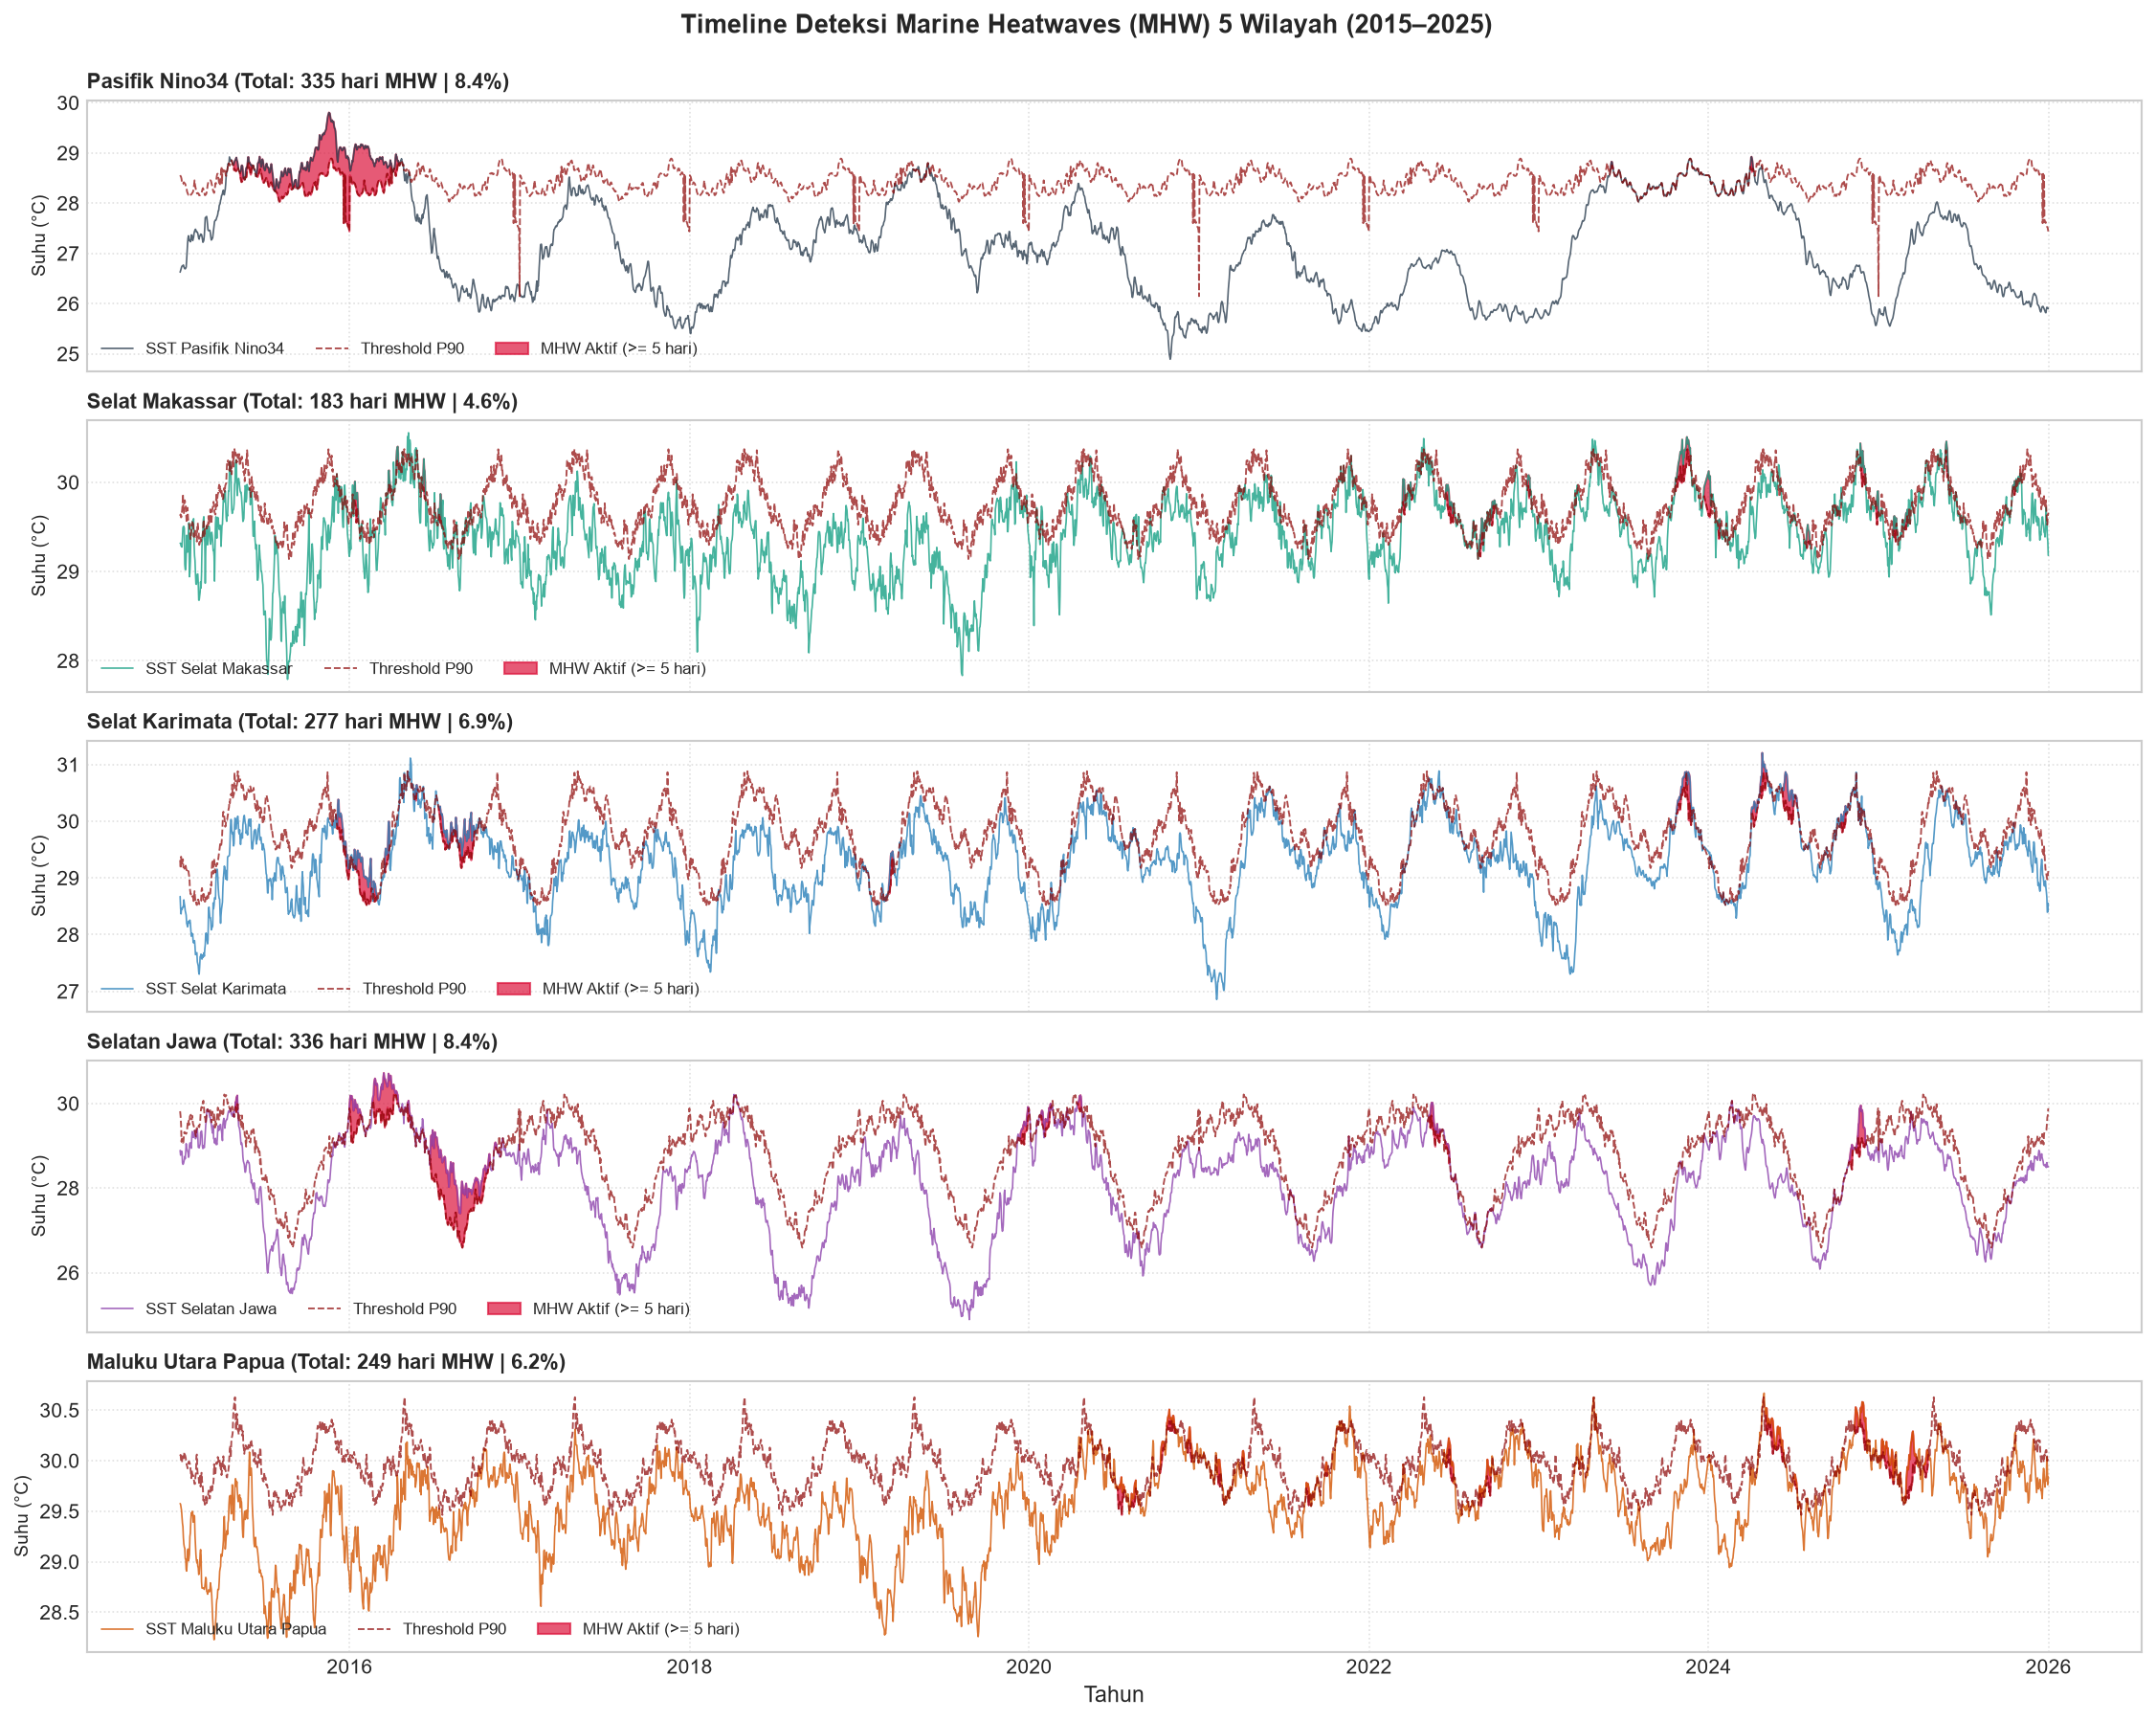

In [3]:
fig, axes = plt.subplots(len(WILAYAH), 1, figsize=(15, 12), sharex=True)

colors_reg = ['#2c3e50', '#16a085', '#2980b9', '#8e44ad', '#d35400']

for idx, region in enumerate(WILAYAH):
    ax = axes[idx]
    sst = df_mhw[f"{region}_sst"]
    p90 = df_mhw[f"{region}_p90"]
    is_mhw = df_mhw[f"{region}_is_mhw"]
    
    # Plot kurva SST dan threshold P90
    ax.plot(df_mhw.index, sst, color=colors_reg[idx], linewidth=0.8, alpha=0.8, label=f"SST {region.replace('_', ' ')}")
    ax.plot(df_mhw.index, p90, color='darkred', linestyle='--', linewidth=0.9, alpha=0.7, label="Threshold P90")
    
    # Shading periode MHW
    ax.fill_between(df_mhw.index, sst, p90, where=(is_mhw == 1), color='crimson', alpha=0.7, label="MHW Aktif (>= 5 hari)")
    
    total_mhw_days = is_mhw.sum()
    pct_mhw = (total_mhw_days / len(df_mhw)) * 100
    ax.set_title(f"{region.replace('_', ' ')} (Total: {total_mhw_days} hari MHW | {pct_mhw:.1f}%)",
                 fontsize=10.5, fontweight='bold', loc='left')
    ax.set_ylabel("Suhu (°C)", fontsize=9)
    ax.legend(loc='lower left', framealpha=0.85, fontsize=8, ncol=3)
    ax.grid(True, linestyle=':', alpha=0.6)

axes[-1].set_xlabel("Tahun", fontsize=11)
plt.suptitle("Timeline Deteksi Marine Heatwaves (MHW) 5 Wilayah (2015–2025)", fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()

fig_path_27 = OUTPUT_DIR / "27_mhw_detection_timeline_5_regions.png"
plt.savefig(fig_path_27)
print(f"Gambar disimpan di: {fig_path_27.resolve()}")
plt.show()

## 4. Statistik Frekuensi, Total Hari, dan Proporsi MHW Antar Wilayah

Bagian ini membandingkan agregasi total hari MHW dan proporsi persentase waktu perairan berada dalam kondisi gelombang panas laut selama 11 tahun terakhir.

C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_15764\2600680344.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_summary_mhw, x='Wilayah', y='Total Hari MHW', ax=axes[0], palette='Reds_r')
C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_15764\2600680344.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(df_summary_mhw['Wilayah'], rotation=25, ha='right')
C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_15764\2600680344.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_summary_mhw, x='Wilayah', y='Proporsi Wak

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\28_mhw_total_days_and_proportion.png


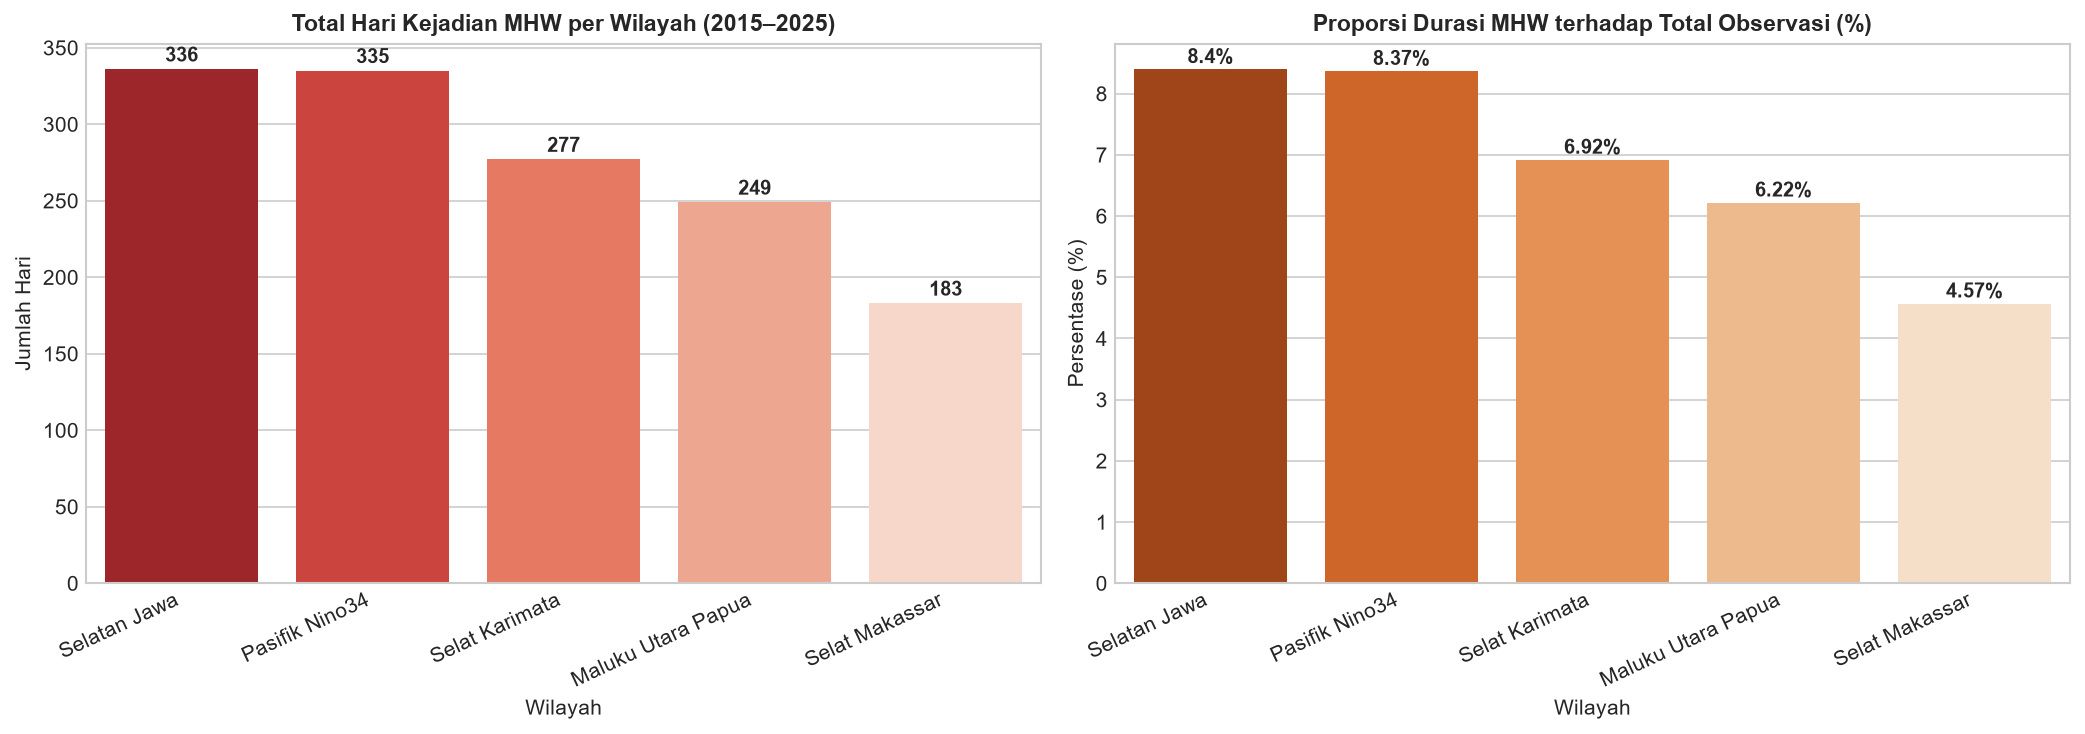

,Wilayah,Total Hari MHW,Proporsi Waktu (%),SST Rata-rata (°C),SST Maksimum (°C)
3,Selatan Jawa,336,8.40,28.13,30.72
0,Pasifik Nino34,335,8.37,27.18,29.81
2,Selat Karimata,277,6.92,29.28,31.21
4,Maluku Utara Papua,249,6.22,29.56,30.67
1,Selat Makassar,183,4.57,29.41,30.56


In [4]:
summary_mhw = []
for region in WILAYAH:
    col = f"{region}_is_mhw"
    days = int(df_mhw[col].sum())
    pct = (days / len(df_mhw)) * 100
    sst_mean = df_mhw[f"{region}_sst"].mean()
    sst_max = df_mhw[f"{region}_sst"].max()
    summary_mhw.append({
        "Wilayah": region.replace('_', ' '),
        "Total Hari MHW": days,
        "Proporsi Waktu (%)": round(pct, 2),
        "SST Rata-rata (°C)": round(sst_mean, 2),
        "SST Maksimum (°C)": round(sst_max, 2)
    })

df_summary_mhw = pd.DataFrame(summary_mhw).sort_values("Total Hari MHW", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Bar chart total hari MHW
sns.barplot(data=df_summary_mhw, x='Wilayah', y='Total Hari MHW', ax=axes[0], palette='Reds_r')
axes[0].set_title("Total Hari Kejadian MHW per Wilayah (2015–2025)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Jumlah Hari")
axes[0].set_xticklabels(df_summary_mhw['Wilayah'], rotation=25, ha='right')
for i, v in enumerate(df_summary_mhw['Total Hari MHW']):
    axes[0].text(i, v + 5, str(v), ha='center', fontweight='bold', fontsize=9.5)

# Plot 2: Persentase proporsi waktu MHW
sns.barplot(data=df_summary_mhw, x='Wilayah', y='Proporsi Waktu (%)', ax=axes[1], palette='Oranges_r')
axes[1].set_title("Proporsi Durasi MHW terhadap Total Observasi (%)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Persentase (%)")
axes[1].set_xticklabels(df_summary_mhw['Wilayah'], rotation=25, ha='right')
for i, v in enumerate(df_summary_mhw['Proporsi Waktu (%)']):
    axes[1].text(i, v + 0.1, f"{v}%", ha='center', fontweight='bold', fontsize=9.5)

plt.tight_layout()
fig_path_28 = OUTPUT_DIR / "28_mhw_total_days_and_proportion.png"
plt.savefig(fig_path_28)
print(f"Gambar disimpan di: {fig_path_28.resolve()}")
plt.show()

display(df_summary_mhw)

## 5. Ekstraksi Metrik Kejadian Individu Hobday (Durasi & Intensitas)

Dalam literatur oseanografi, gelombang panas laut tidak hanya dihitung sebagai total hari, tetapi diekstrak menjadi **kejadian diskret (*discrete events*)**:
- **Duration ($D$)**: Jumlah hari berturut-turut kondisi MHW berlangsung ($D \ge 5$).
- **Maximum Intensity ($I_{max}$)**: Selisih puncak maksimum antara suhu aktual dengan threshold ($SST - P_{90}$).
- **Mean Intensity ($I_{mean}$)**: Rata-rata anomali di atas ambang selama periode peristiwa.
- **Cumulative Intensity ($I_{cum}$)**: Akumulasi stres termal total ($\sum (SST - P_{90})$ dalam $^\circ	ext{C}\cdot	ext{hari}$).

C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_15764\2825021831.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_events, x='Wilayah', y='Duration', ax=axes[0], palette='Set2')
C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_15764\2825021831.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha='right')


Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\29_mhw_duration_intensity_metrics.png


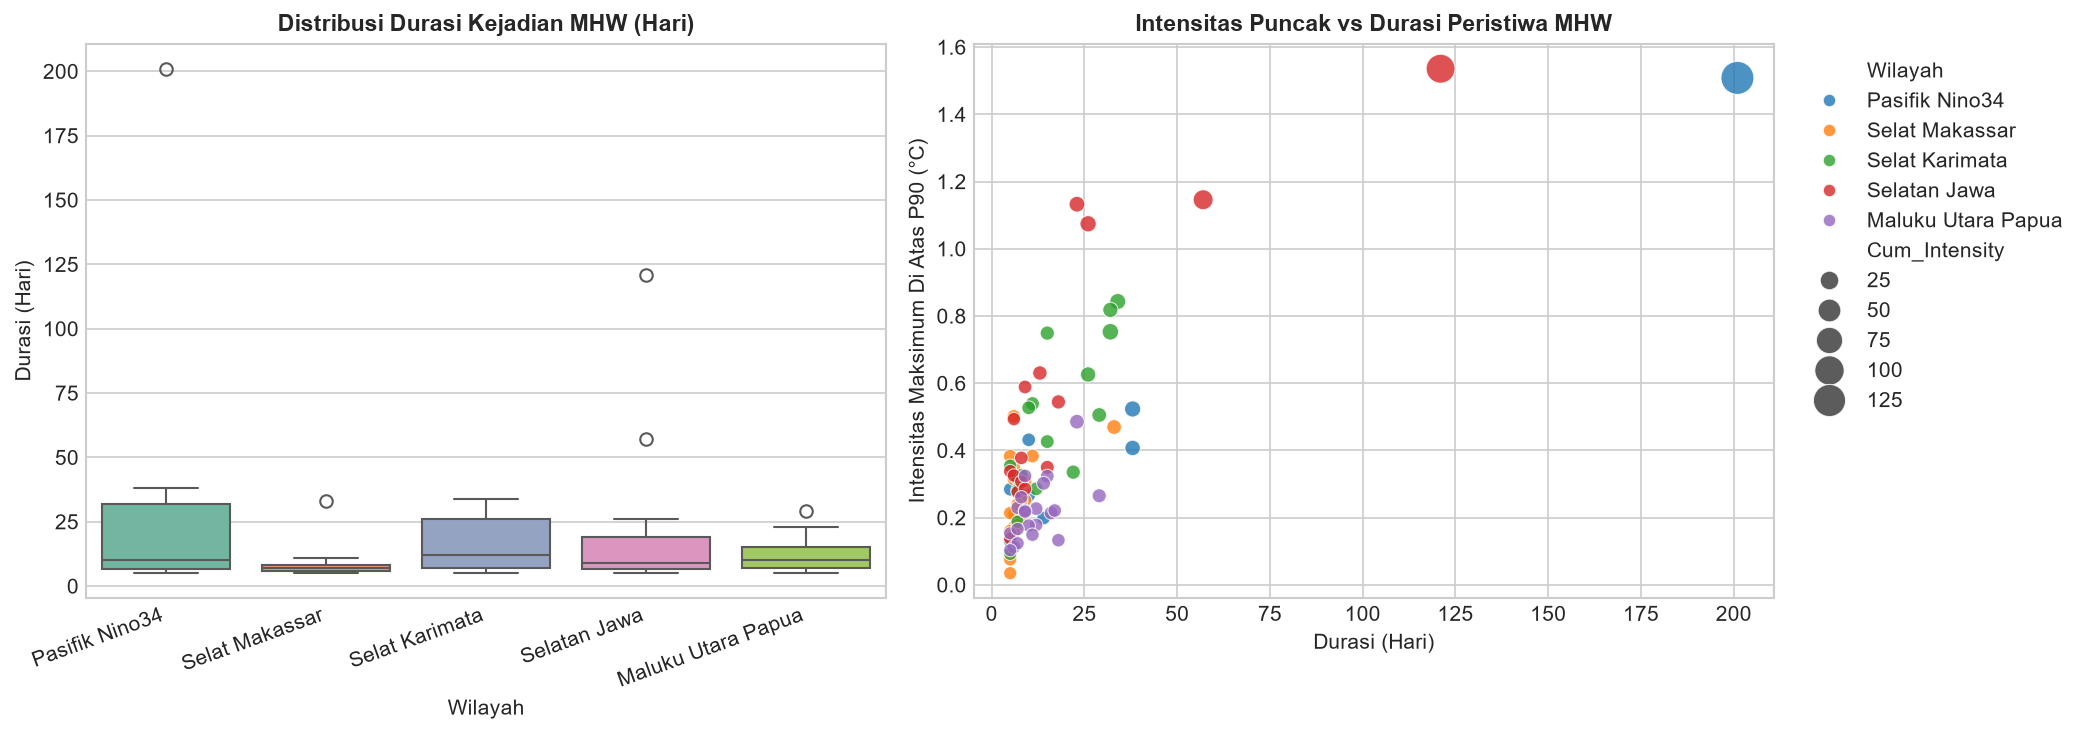

Duration             Max_Intensity       Cum_Intensity  \
                      count   mean  max          mean   max          mean   
Wilayah                                                                     
Maluku Utara Papua       21  11.86   29          0.22  0.49          1.59   
Pasifik Nino34           10  33.50  201          0.42  1.51         16.39   
Selat Karimata           17  16.29   34          0.47  0.84          4.47   
Selat Makassar           23   7.96   33          0.26  0.50          1.27   
Selatan Jawa             16  21.00  121          0.60  1.54         11.10   

                            
                       max  
Wilayah                     
Maluku Utara Papua    6.17  
Pasifik Nino34      132.60  
Selat Karimata       14.62  
Selat Makassar        6.38  
Selatan Jawa         96.10

In [5]:
# Fungsi ekstraksi peristiwa diskret MHW
def extract_mhw_events(df, region):
    is_mhw = df[f"{region}_is_mhw"].values
    sst = df[f"{region}_sst"].values
    p90 = df[f"{region}_p90"].values
    dates = df.index
    
    events = []
    in_event = False
    start_idx = 0
    
    for i in range(len(is_mhw)):
        if is_mhw[i] == 1 and not in_event:
            in_event = True
            start_idx = i
        elif is_mhw[i] == 0 and in_event:
            in_event = False
            duration = i - start_idx
            event_sst = sst[start_idx:i]
            event_p90 = p90[start_idx:i]
            intensity = event_sst - event_p90
            
            events.append({
                "Wilayah": region.replace('_', ' '),
                "Start_Date": dates[start_idx],
                "End_Date": dates[i - 1],
                "Duration": duration,
                "Max_Intensity": np.max(intensity),
                "Mean_Intensity": np.mean(intensity),
                "Cum_Intensity": np.sum(intensity)
            })
            
    # Tangani jika event berlangsung hingga akhir data
    if in_event:
        duration = len(is_mhw) - start_idx
        event_sst = sst[start_idx:]
        event_p90 = p90[start_idx:]
        intensity = event_sst - event_p90
        events.append({
            "Wilayah": region.replace('_', ' '),
            "Start_Date": dates[start_idx],
            "End_Date": dates[-1],
            "Duration": duration,
            "Max_Intensity": np.max(intensity),
            "Mean_Intensity": np.mean(intensity),
            "Cum_Intensity": np.sum(intensity)
        })
        
    return pd.DataFrame(events)

all_events = pd.concat([extract_mhw_events(df_mhw, reg) for reg in WILAYAH], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Boxplot Durasi Peristiwa MHW (Hari)
sns.boxplot(data=all_events, x='Wilayah', y='Duration', ax=axes[0], palette='Set2')
axes[0].set_title("Distribusi Durasi Kejadian MHW (Hari)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Durasi (Hari)")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha='right')

# Plot 2: Scatter / Strip plot Intensitas Maksimum vs Durasi
sns.scatterplot(data=all_events, x='Duration', y='Max_Intensity', hue='Wilayah',
                size='Cum_Intensity', sizes=(40, 250), ax=axes[1], alpha=0.8, palette='tab10')
axes[1].set_title("Intensitas Puncak vs Durasi Peristiwa MHW", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Durasi (Hari)")
axes[1].set_ylabel("Intensitas Maksimum Di Atas P90 (°C)")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
fig_path_29 = OUTPUT_DIR / "29_mhw_duration_intensity_metrics.png"
plt.savefig(fig_path_29)
print(f"Gambar disimpan di: {fig_path_29.resolve()}")
plt.show()

# Ringkasan metrik per wilayah
event_metrics_summary = all_events.groupby('Wilayah').agg({
    'Duration': ['count', 'mean', 'max'],
    'Max_Intensity': ['mean', 'max'],
    'Cum_Intensity': ['mean', 'max']
}).round(2)
display(event_metrics_summary)

## 6. Tren Tahunan Kejadian MHW (2015–2025)

Apakah pemanasan global meningkatkan jumlah hari dan intensitas gelombang panas laut seiring waktu?
Di bawah ini kita mengelompokkan jumlah hari MHW berdasarkan tahun kalender untuk masing-masing wilayah.

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\30_mhw_annual_trends_2015_2025.png


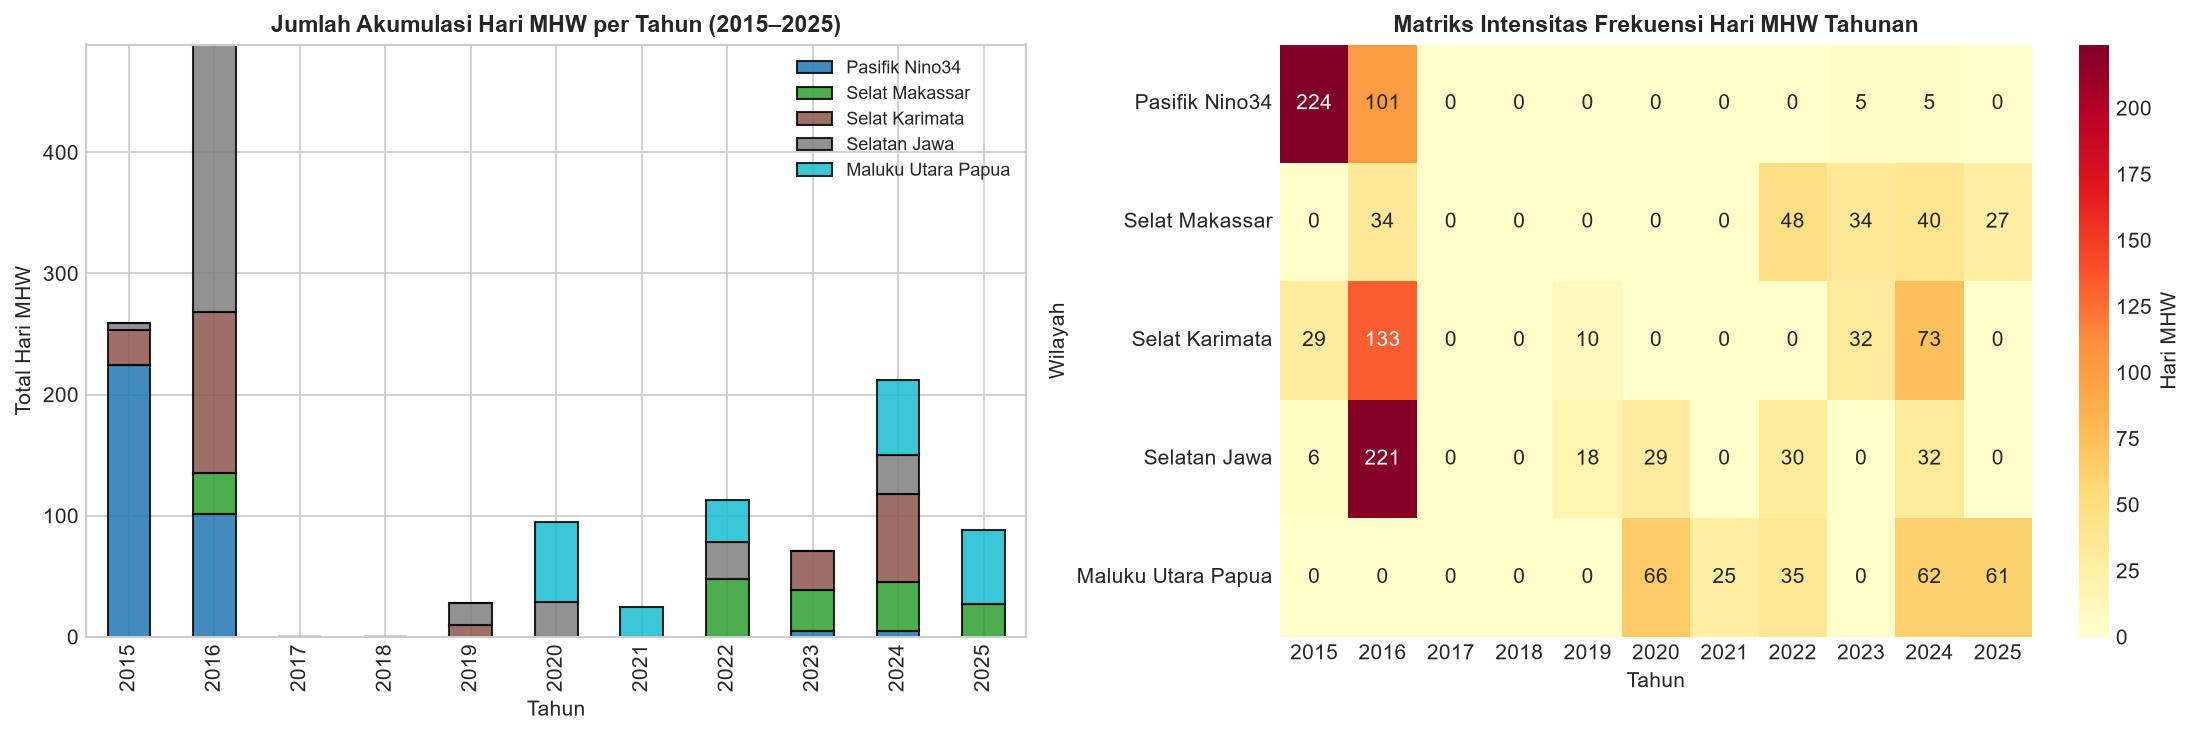

In [6]:
# Menghitung hari MHW per tahun
df_mhw['Year'] = df_mhw.index.year
annual_mhw = {}
for reg in WILAYAH:
    annual_mhw[reg.replace('_', ' ')] = df_mhw.groupby('Year')[f"{reg}_is_mhw"].sum()

df_annual_mhw = pd.DataFrame(annual_mhw)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Stacked bar chart jumlah hari MHW per tahun
df_annual_mhw.plot(kind='bar', stacked=True, ax=axes[0], colormap='tab10', edgecolor='black', alpha=0.85)
axes[0].set_title("Jumlah Akumulasi Hari MHW per Tahun (2015–2025)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Tahun")
axes[0].set_ylabel("Total Hari MHW")
axes[0].legend(loc='upper right', fontsize=8.5)

# Plot 2: Heatmap Tahun vs Wilayah
sns.heatmap(df_annual_mhw.T, cmap='YlOrRd', annot=True, fmt='d', ax=axes[1], cbar_kws={'label': 'Hari MHW'})
axes[1].set_title("Matriks Intensitas Frekuensi Hari MHW Tahunan", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Tahun")
axes[1].set_ylabel("Wilayah")

plt.tight_layout()
fig_path_30 = OUTPUT_DIR / "30_mhw_annual_trends_2015_2025.png"
plt.savefig(fig_path_30)
print(f"Gambar disimpan di: {fig_path_30.resolve()}")
plt.show()

## 7. Variasi Musiman Bulanan Kejadian MHW

Pada bulan apa perairan Indonesia dan Pasifik paling rentan mengalami stres panas MHW?
Analisis distribusi bulanan mengungkap peran sistem angin monsun Asia–Australia terhadap modulasi MHW.

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\31_mhw_monthly_seasonality.png


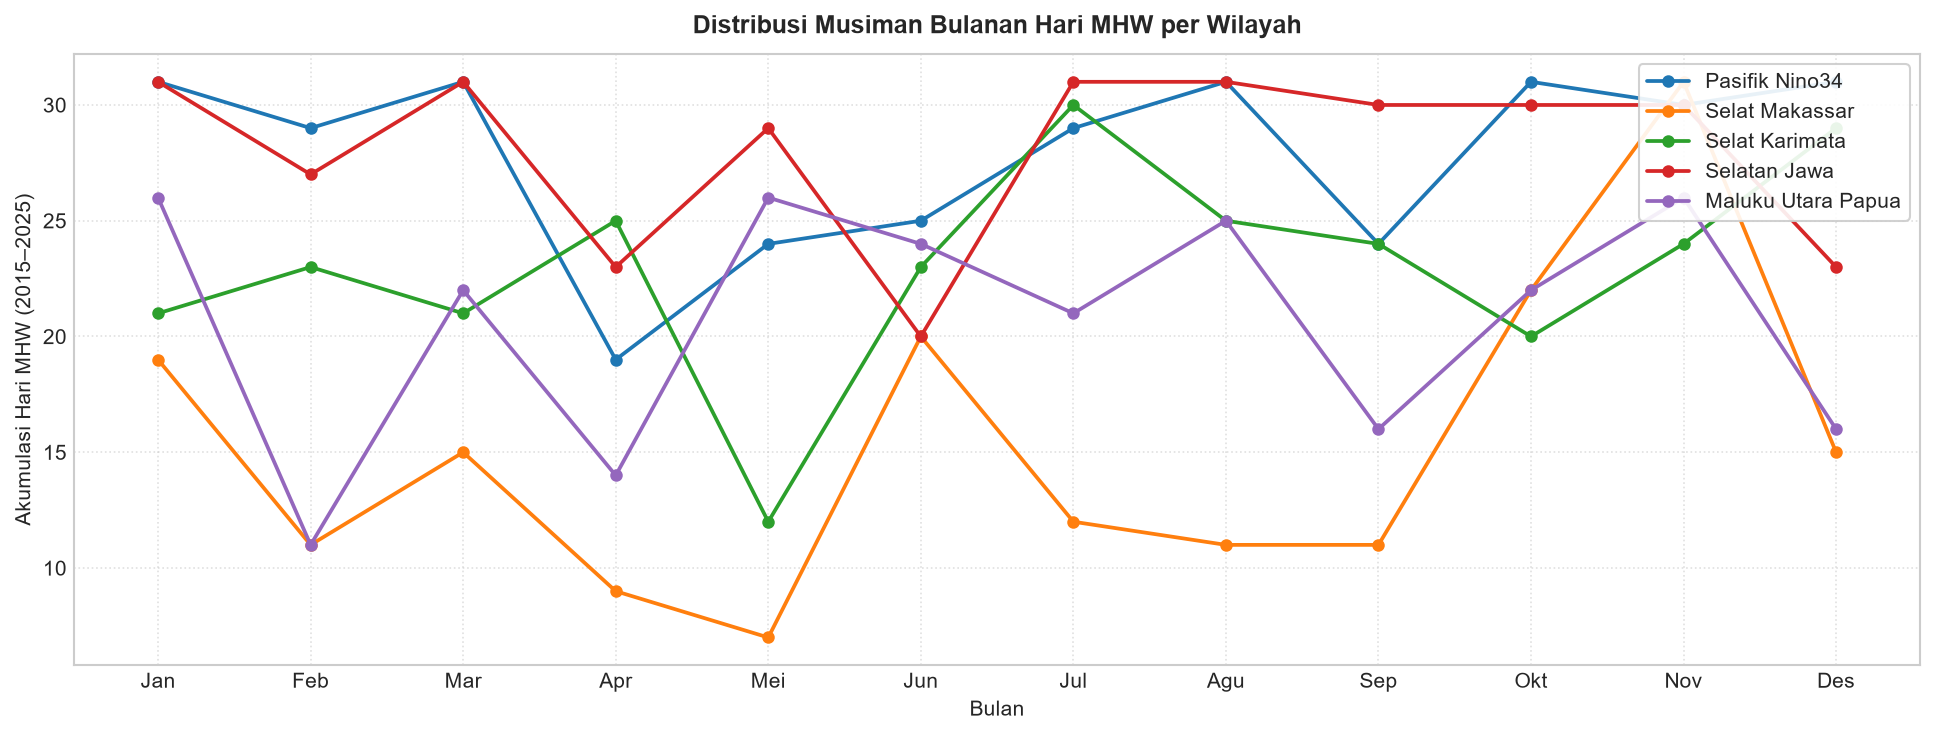

In [7]:
df_mhw['Month'] = df_mhw.index.month
monthly_mhw = {}
for reg in WILAYAH:
    monthly_mhw[reg.replace('_', ' ')] = df_mhw.groupby('Month')[f"{reg}_is_mhw"].sum()

df_monthly_mhw = pd.DataFrame(monthly_mhw)
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
df_monthly_mhw.index = month_names

fig, ax = plt.subplots(figsize=(13, 5))
df_monthly_mhw.plot(ax=ax, marker='o', linewidth=1.8, markersize=5)
ax.set_title("Distribusi Musiman Bulanan Hari MHW per Wilayah", fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel("Bulan", fontsize=10)
ax.set_ylabel("Akumulasi Hari MHW (2015–2025)", fontsize=10)
ax.set_xticks(range(12))
ax.set_xticklabels(month_names)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right', frameon=True, framealpha=0.9)
plt.tight_layout()

fig_path_31 = OUTPUT_DIR / "31_mhw_monthly_seasonality.png"
plt.savefig(fig_path_31)
print(f"Gambar disimpan di: {fig_path_31.resolve()}")
plt.show()

## 8. Ko-insidensi Spasial & Hubungan dengan Fase ENSO

Apakah gelombang panas laut terjadi serentak di seluruh perairan Indonesia ketika terjadi El Niño di Pasifik?
Di bawah ini kita menghitung **Matriks Kesamaan Jaccard** (tingkat tumpang tindih waktu MHW antar wilayah) dan mengevaluasi ko-insidensi kejadian MHW dengan tahun El Niño kuat (2015/16 dan 2023/24).

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\32_mhw_spatial_coincidence_matrix.png


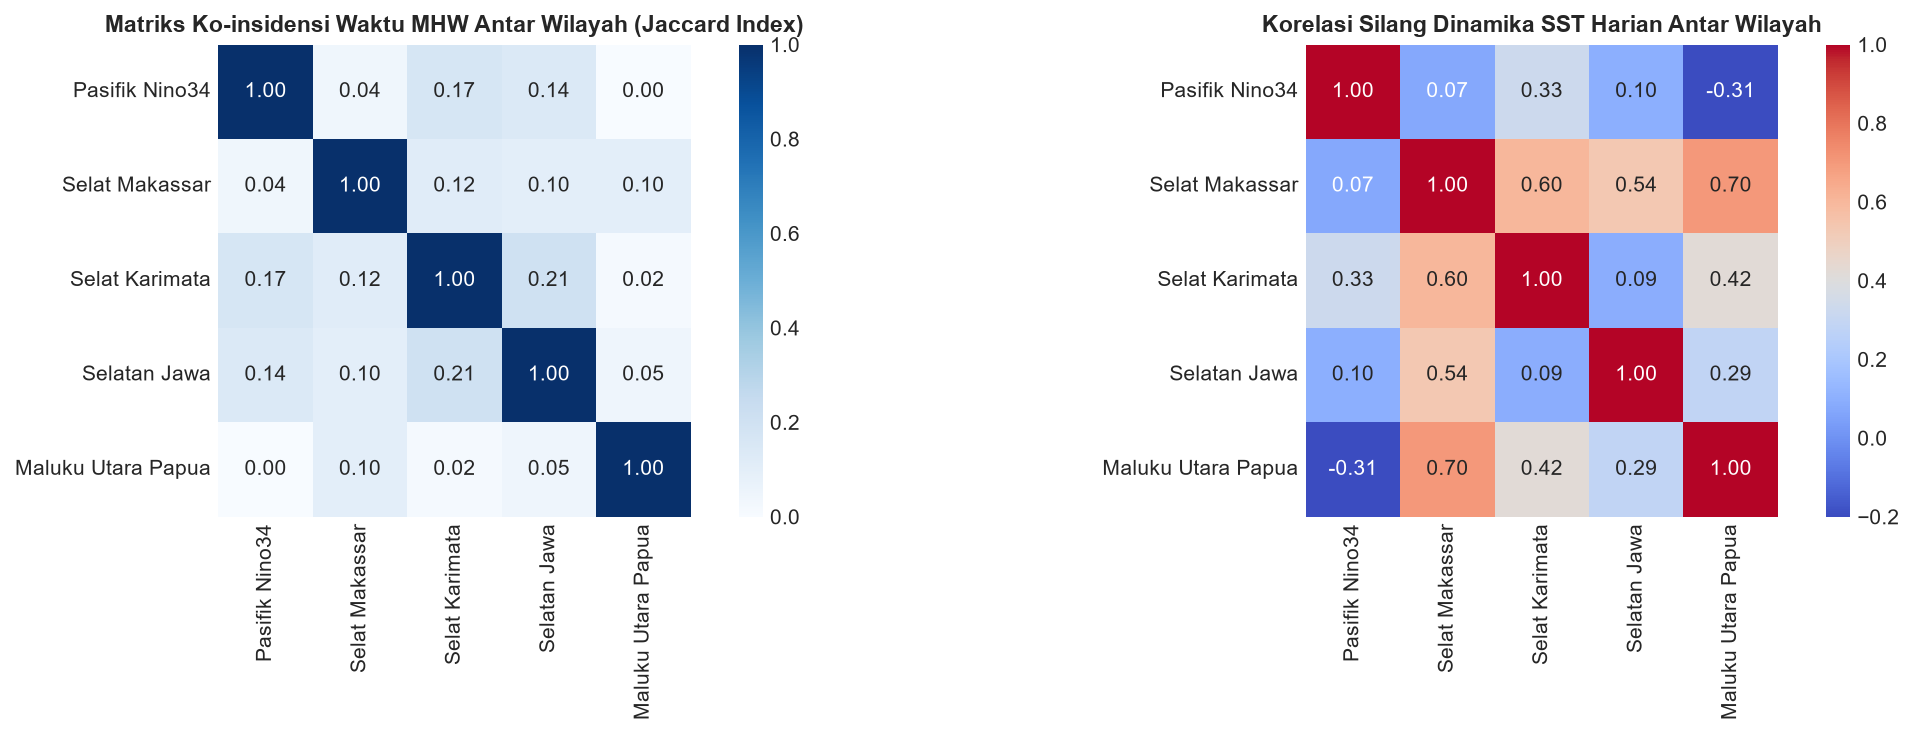

In [8]:
# Menghitung Matriks Jaccard Similarity antar wilayah untuk status MHW
jaccard_matrix = np.zeros((len(WILAYAH), len(WILAYAH)))

for i, reg_a in enumerate(WILAYAH):
    for j, reg_b in enumerate(WILAYAH):
        a = df_mhw[f"{reg_a}_is_mhw"].values == 1
        b = df_mhw[f"{reg_b}_is_mhw"].values == 1
        intersection = np.logical_and(a, b).sum()
        union = np.logical_or(a, b).sum()
        jaccard_matrix[i, j] = intersection / union if union > 0 else 0

reg_labels = [r.replace('_', ' ') for r in WILAYAH]
df_jaccard = pd.DataFrame(jaccard_matrix, index=reg_labels, columns=reg_labels)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Heatmap Jaccard Similarity (Ko-insidensi spasial)
sns.heatmap(df_jaccard, annot=True, cmap='Blues', fmt='.2f', ax=axes[0], square=True)
axes[0].set_title("Matriks Ko-insidensi Waktu MHW Antar Wilayah (Jaccard Index)", fontsize=11, fontweight='bold')

# Plot 2: Korelasi Ko-Evolusi Suhu Harian (SST Pearson)
corr_sst = df_mhw[[f"{r}_sst" for r in WILAYAH]].corr()
corr_sst.index = reg_labels
corr_sst.columns = reg_labels
sns.heatmap(corr_sst, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1], square=True, vmin=-0.2, vmax=1.0)
axes[1].set_title("Korelasi Silang Dinamika SST Harian Antar Wilayah", fontsize=11, fontweight='bold')

plt.tight_layout()
fig_path_32 = OUTPUT_DIR / "32_mhw_spatial_coincidence_matrix.png"
plt.savefig(fig_path_32)
print(f"Gambar disimpan di: {fig_path_32.resolve()}")
plt.show()

## 9. Kesimpulan & Relevansi terhadap Pemodelan

1. **Frekuensi & Durasi**: Wilayah **Selatan Jawa** dan **Pasifik Niño 3.4** mencatatkan total hari MHW tertinggi (~335–336 hari), sementara Selat Makassar memiliki kejadian paling sedikit (183 hari).
2. **Karakteristik Kejadian Ekstrem**: Peristiwa MHW individu memiliki rentang durasi dari 5 hari hingga beberapa puluh hari pada tahun-tahun panas ekstrem. Intensitas maksimum di atas ambang batas $P_{90}$ dapat melampaui 1.5°C–2.0°C.
3. **Puncak Kejadian Tahunan**: Peningkatan tajam hari MHW sangat terkonsentrasi pada tahun **2016** dan **2023–2024**, membuktikan adanya keterkaitan kuat antara panas laut ekstrem dengan fase El Niño kuat.
4. **Implikasi Target Prediksi**: Label biner MHW yang disediakan ini sangat cocok digunakan sebagai target klasifikasi peristiwa ekstrem (*rare event detection / imbalanced classification*) untuk model peringatan dini gelombang panas laut di Indonesia.